# 04c — Real weather forecasts: GFS runs published before issuance (stage 6b)

**Purpose.** Give the models a weather forecast that was really available at the issuance time
T0 (00:00 local of the first forecast day), then test on validation whether it helps (D-12).

**Why.** The original pipeline used an Open-Meteo archive series valued at the target hour: not
a forecast that existed at T0, so it was leakage, and it was removed from the final models (C-06,
F-11). The backup of the original project shows the exact request (F-28,
`00b_original_backup_review.ipynb`). The report's first Future Work item asks for genuine NWP.

**Source.** The NOAA GFS archive on AWS, 1°, the 12Z run of each day, leads 9–84 h, eleven
fields. **Outputs.** `data/processed/06b_gfs/gfs_features_D{h}.parquet`,
`outputs/06b_gfs/`, `configs/nwp_decision.yaml`.

**Rules.** A run may serve T0 only if it started at least 6 h before T0 **and** every one of its
files was uploaded before T0 (T-17, checked row by row). Statistics on train and validation; the
test split is not read. **Documented in** OP-42 to OP-44, run journal R6b-01 to R6b-08,
`docs/stage6b_plan.md`.

## 1. Was every run public before T0?

,count,mean,std,min,25%,50%,75%,max
status,,,,,,,,
complete,1371.0,5.51,0.58,1.09,5.08,5.13,6.09,12.00
rejected_late_upload,2.0,-0.76,0.92,-1.40,-1.08,-0.76,-0.43,-0.11


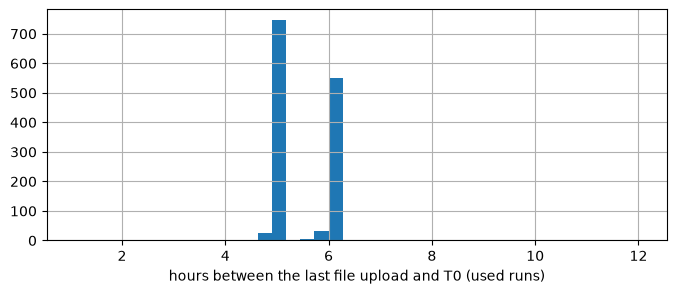

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from solarpv.nwp import download

records = [json.loads(p.read_text(encoding="utf-8"))
           for p in sorted(download.OUT_DIR.glob("*/*.json"))]
rows = []
for r in records:
    t0 = download.issuance_of_run_day(r["day"])
    last = max(pd.Timestamp(f["uploaded_utc"]) for f in r["files"])
    rows.append({"day": r["day"], "run": r["run"], "status": r.get("status"),
                 "hours_last_upload_before_t0": (t0 - last).total_seconds() / 3600})
runs = pd.DataFrame(rows)
display(runs.groupby("status")["hours_last_upload_before_t0"].describe().round(2))
runs.loc[runs["status"] == "complete", "hours_last_upload_before_t0"].hist(bins=40, figsize=(8, 3))
plt.xlabel("hours between the last file upload and T0 (used runs)");

**What it shows.** For every run, the time between the upload of its last file and the T0
it serves.
- **Used runs:** 1,371 (2 of them from the 06Z run of the day). The
  smallest margin is 1.1 h: every file of every used run was public before T0.
- **Rejected runs:** 2 (2022-01-24, 2022-07-23). A file was re-uploaded after T0.
  The archive keeps only the latest version, so the version public at T0 cannot be shown; the
  earlier run of the same day is used instead.

**In the original** the series had no issue time at all.

## 2. From 3-hour averages to hourly values

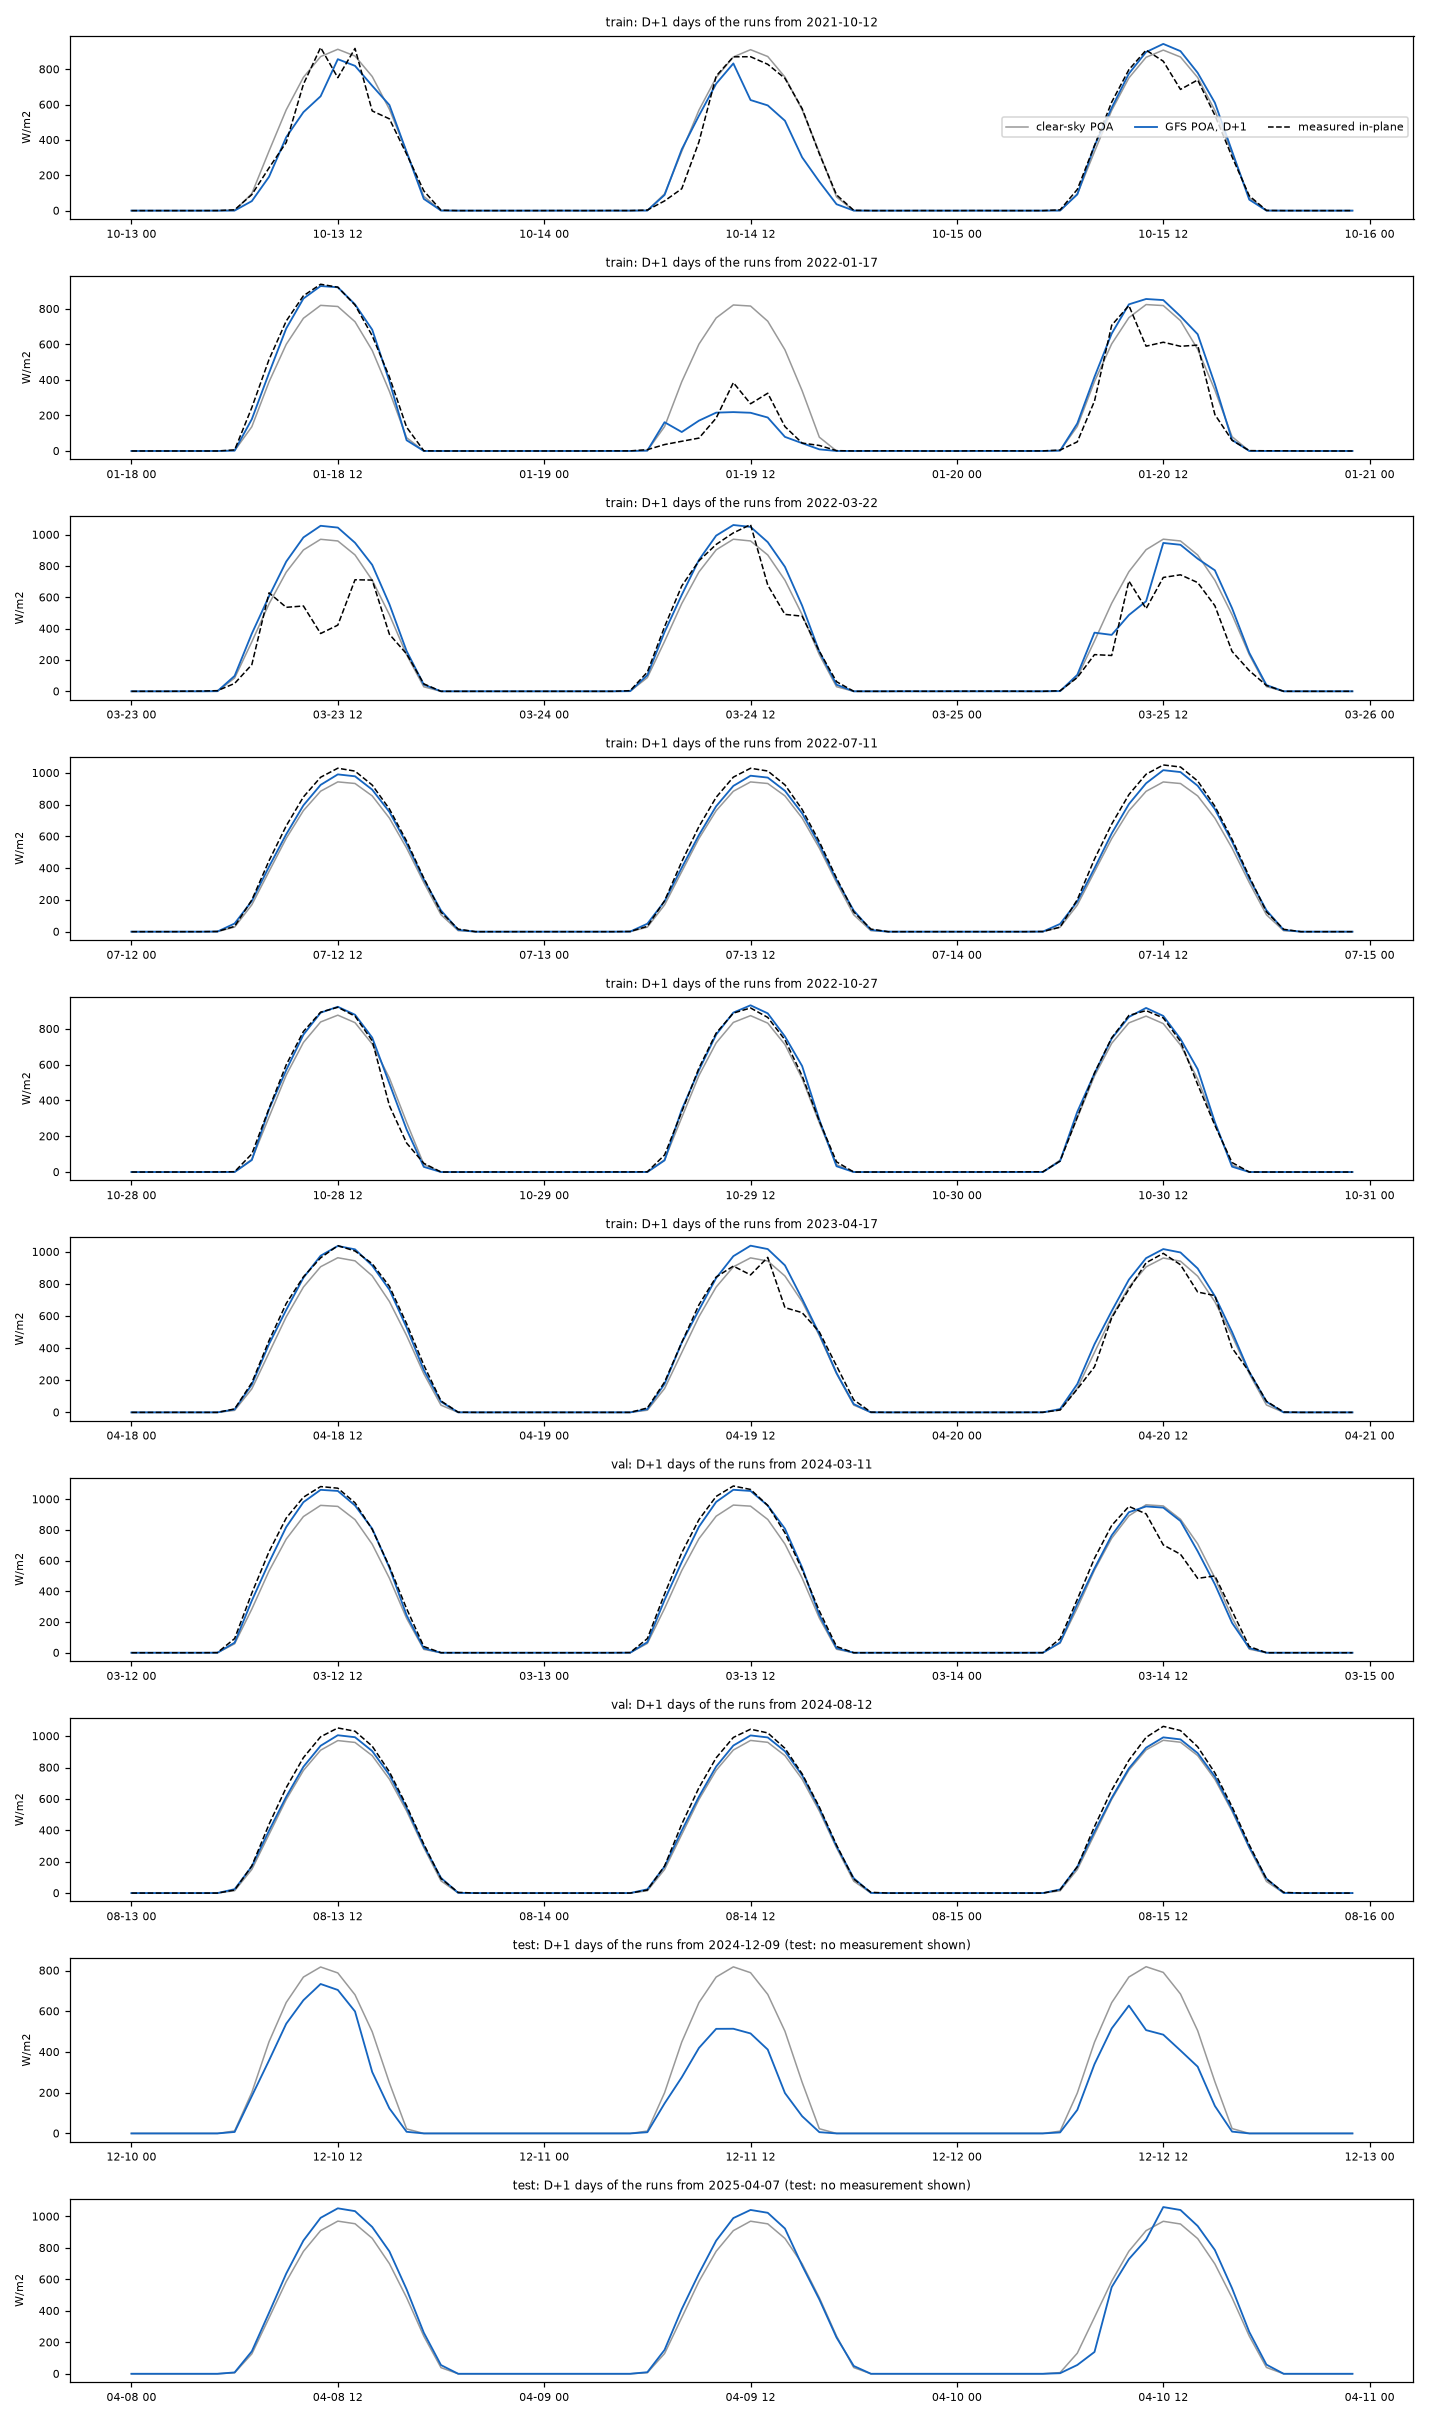

In [2]:
display(Image("../00_data_audit/gfs_sample_2026-10-25/sample_days.png", width=950))

**What it shows.** Three-day windows from ten periods, checked before the full download:
the clear-sky irradiance on the panel plane (grey), the GFS D+1 forecast on the panel plane after
the reconstruction (blue) and the measured in-plane irradiance (dashed). The test windows show
no measurement. The forecast follows clear days closely and catches the overcast day of
19 January 2022; on broken-cloud days (March 2022) it gets the level of the day but not the
timing of single clouds.

**How it is built (OP-43).** GFS stores irradiance as averages from the start of a 6-hour window.
They are turned back into 3-hour means, then spread over the hours in proportion to the clear-sky
irradiance, so the 3-hour mean is kept and dark hours get zero. The panel-plane irradiance, cell
temperature and physical PV power follow from a physical chain (Erbs, Hay-Davies, Faiman).

In [3]:
dictionary = pd.read_csv("../outputs/06b_gfs/gfs_feature_dictionary.csv")
dictionary[["feature", "unit", "idea"]]

,feature,unit,idea
0,fcst_gfs_ghi,W/m2,L-06
1,fcst_gfs_kt,-,L-03
2,fcst_gfs_poa,W/m2,L-01
3,fcst_gfs_kt_poa,-,L-03
4,fcst_gfs_kt_poa_ma3,-,L-02
5,fcst_gfs_kt_poa_daymean,-,L-02
6,fcst_gfs_tcc,%,L-07
7,fcst_gfs_lcc,%,L-07
8,fcst_gfs_mcc,%,L-07
9,fcst_gfs_hcc,%,L-07


**What it shows.** The 22 candidates per horizon, with their literature idea
(L-01 to L-11). One of them, `irradiance_clear_index_prevday`, is not from GFS: yesterday's
measured clear-sky index (L-11a). Each horizon has its own leads: D+1 uses hours 10–34 after the
run start, D+3 hours 58–82.

## 3. Sanity: does the forecast behave like a forecast?

In [4]:
sanity = json.loads(open("../outputs/06b_gfs/sanity.json", encoding="utf-8").read())
display(pd.DataFrame(sanity["horizon_skill"]).round(3))
pd.Series(sanity["lag_correlations_train"], name="r by lag (h)").to_frame().T

,horizon,hours,days,corr_hourly,corr_daily,bias,mae
0,1,11659,1124,0.642,0.819,-0.011,0.096
1,2,11659,1124,0.624,0.791,-0.013,0.098
2,3,11659,1124,0.578,0.738,-0.013,0.103


,-3,-2,-1,0,1,2,3
r by lag (h),0.1914,0.4908,0.799,0.9597,0.8411,0.5671,0.2786


**What it shows.** The GFS clear-sky index on the panel plane against the measured one,
on the same 1,124 train and validation days for every horizon; and, on
train, the correlation at hourly shifts of −3 to +3 h.

**What it means.**
- **Skill falls with the horizon**, as it must: daily r 0.82 /
  0.79 / 0.74.
- **The best lag is 0 h:** the time alignment is right.
- **Neither red flag of the plan is raised:** "too good at D+3"
  (False) and "skill rising with the horizon"
  (False).
- **The seasonal bias is small:** between -0.025 and
  +0.012.

## 4. Does it help? The value check (D-12)

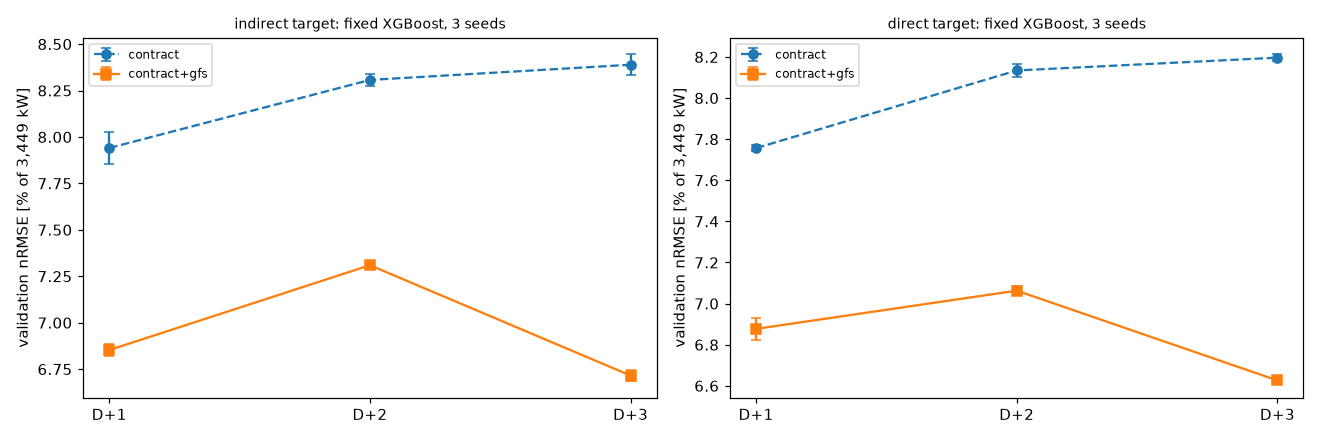

features          contract  contract+gfs
target   horizon                        
direct   1            7.76          6.88
         2            8.13          7.06
         3            8.20          6.63
indirect 1            7.94          6.85
         2            8.31          7.31
         3            8.39          6.72

In [5]:
display(Image("../outputs/06b_gfs/value_check.png", width=850))
pd.read_csv("../outputs/06b_gfs/value_check.csv").pivot_table(
    index=["target", "horizon"], columns="features", values="nrmse_kw_mean").round(2)

**What it shows.** The fixed XGBoost of D-11 (three seeds), trained on train and scored
on validation, with the stage-6 contract alone and with the GFS candidates added. nRMSE in % of the
3,449 kW capacity.

**What it means.** GFS lowers the error at every horizon and for both targets, by
0.88–1.67 points, against margins of at most
0.13 points (rule fixed before the run). **Decision (D-12): admitted**
(`configs/nwp_decision.yaml`). Stage 7 selects among the candidates.

## 5. A red flag examined: D+3 better than D+1 on validation

In [6]:
diag = pd.read_csv("../00_data_audit/gfs_value_2026-10-25/diagnose_sample.csv")
display(diag.pivot_table(index=["target", "sample"], columns="horizon", values="nrmse_kw").round(2))
pd.read_csv("../00_data_audit/gfs_value_2026-10-25/diagnose_sample_bootstrap.csv").round(3)

horizon                                   1     2     3
target   sample                                        
direct   inner (train, after 2023-04)  7.24  7.56  7.72
         validation                    6.85  7.08  6.58
indirect inner (train, after 2023-04)  7.17  7.51  7.71
         validation                    6.83  7.18  6.62

,target,diff_D3_minus_D1_pp,ci_lo,ci_hi
0,indirect,-0.204,-0.486,0.031
1,direct,-0.270,-0.586,0.028


**What it shows.** With GFS, D+3 scored better than D+1 on validation
(6.62 against 6.83 for the
indirect target). Forecasts lose skill with the horizon, so this was checked before going on.

**The checks.**
- **Horizon mapping:** correct; the leads are as designed.
- **Inner period of train** (fit to April 2023, scored May 2023 to January 2024): the expected
  order D+1 < D+2 < D+3, 7.17 /
  7.51 /
  7.71.
- **Paired bootstrap on validation:** the 95 % interval of RMSE(D+3) − RMSE(D+1) includes zero:
  indirect -0.49 to +0.03 points.

**Conclusion.** A property of the validation sample (GFS at D+3 happened to be as good as at D+1
there), not a leak.

**Next stage.** Stage 7, feature selection, with the admitted candidates.

**Reproduce.** `python -m solarpv.nwp.download` (about 26 GB of transfer, resumable),
`python -m solarpv.nwp.gfs`, `python -m solarpv.nwp.check`, then
`python scripts/make_nwp_gfs_notebook.py`.